In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [5]:
def srgb_encode(x):
    """Gamma sRGB (linear [0,1] -> encoded [0,1])."""
    x = np.clip(x, 0.0, 1.0)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * x ** (1 / 2.4) - 0.055)
def to_display(lin_srgb, ev=0.0):
    return srgb_encode(lin_srgb * 2.0 ** ev)

In [6]:
def show_row(images, titles, ev=0.0, size=3.2):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(to_display(img, ev))
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [11]:

from acr_tone_fast import finish
from dataset_sim import square_resize, jpeg_roundtrip
u8 =lambda a: square_resize(finish(a, ev=0.0, tone=True), CULL_SIZE, None)
transform = lambda b: jpeg_roundtrip(u8(b), 95, "444").astype(np.float32) / 255.

def psnr_raw_to_jpeg(M,T):
    M, T = transform(M), transform(T)
    return 10 * np.log10(1. / max(float(((M - T) ** 2).mean()), 1e-12))

ModuleNotFoundError: No module named 'acr_tone_fast'

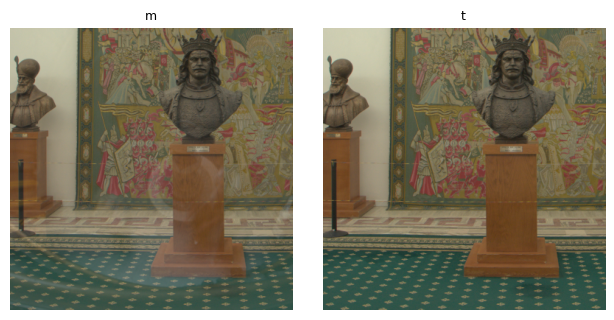

In [7]:
z_ibl = np.load("/home/damien/data_fivek_dng/dataset_weak_24dB_27_5dB/ex_00000_00.npz")
zm, zt = z_ibl["m"].astype(np.float32), z_ibl["true_t"].astype(np.float32)
show_row([zm, zt], ["m", "t"])